# 03 – Phân khúc khách hàng RFM bằng K-Means

Công việc 3.3: chọn số cụm, gán nhãn phân khúc, so sánh với phiên bản lỗi.

> **Quyền riêng tư:** `customer_id` được dựng từ số điện thoại khách hàng. Notebook chỉ hiển thị số liệu tổng hợp hoặc mã đã che (`KH_0908***444`). Không in trực tiếp cột `customer_id` / `bill_phone_number` / `bill_full_name`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # bảng màu đã kiểm định CVD
from backend.ml import feature_engineering as fe
from backend.app.core.customer_store import mask_customer_id  # che số điện thoại khi hiển thị

## 1. Dữ liệu RFM
F = **số đơn mua thành công**, M = tổng giá trị đơn thành công; F và M lấy log(1 + x) rồi chuẩn hóa z-score.

In [2]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

rfm = fe.read_csv("customer_rfm_features.csv")
X = fe.rfm_feature_frame(rfm["recency_days"], rfm["completed_orders"], rfm["monetary_total"])
Xs = StandardScaler().fit_transform(X)
rfm[["recency_days", "completed_orders", "monetary_total"]].describe().round(1)

,recency_days,completed_orders,monetary_total
count,19100.0,19100.0,19100.0
mean,15.7,0.8,270472.1
std,10.3,0.5,216585.7
min,1.0,0.0,0.0
25%,7.0,1.0,150000.0
50%,14.0,1.0,300000.0
75%,24.0,1.0,380000.0
max,153.0,6.0,4688000.0


## 2. Chọn K: Elbow và Silhouette

,SSE,Silhouette
K,,
2,20802.017,0.688
3,12490.196,0.595
4,6373.408,0.636
5,4674.889,0.665
6,3590.470,0.616
7,3070.901,0.603
8,2543.093,0.569


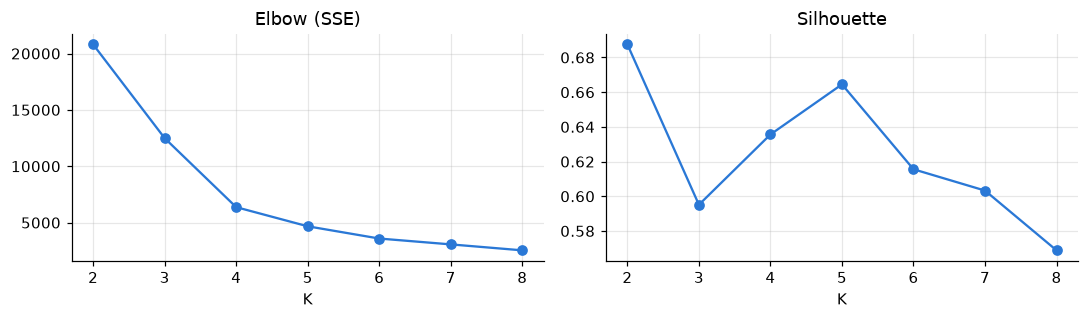

In [3]:
rng = np.random.RandomState(42); sample = rng.choice(len(Xs), 5000, replace=False)
rows = []
for k in range(2, 9):
    km = KMeans(k, random_state=42, n_init=10).fit(Xs)
    rows.append({"K": k, "SSE": km.inertia_, "Silhouette": silhouette_score(Xs[sample], km.labels_[sample])})
sel = pd.DataFrame(rows).set_index("K")
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sel["SSE"].plot(ax=axes[0], marker="o", color=C[0], title="Elbow (SSE)")
sel["Silhouette"].plot(ax=axes[1], marker="o", color=C[0], title="Silhouette")
plt.tight_layout()
sel.round(3)

K = 2 chỉ tách *đã mua / chưa mua*. Trong K ∈ [4, 8] (đủ 4 phân khúc nghiệp vụ), chọn Silhouette cao nhất.

In [4]:
k_best = sel.loc[4:].Silhouette.idxmax(); print("K được chọn:", k_best)
km = KMeans(k_best, random_state=42, n_init=10).fit(Xs)
seg_map = fe.rank_rfm_centroids(km.cluster_centers_)
rfm["cluster"], rfm["segment"] = km.labels_, pd.Series(km.labels_).map(seg_map).values
prof = rfm.groupby(["segment", "cluster"]).agg(so_khach=("cluster", "size"), R_tb=("recency_days", "mean"),
                                                F_tb=("completed_orders", "mean"), ty_le_mua_lai=("completed_orders", lambda s: (s >= 2).mean()),
                                                M_trung_vi=("monetary_total", "median"))
prof["ty_trong"] = prof["so_khach"] / len(rfm)
prof.round(3)

K được chọn: 5


so_khach    R_tb   F_tb  ty_le_mua_lai  M_trung_vi  \
segment      cluster                                                       
Cần chăm sóc 2            6295  25.386  1.006          0.006    300000.0   
Rủi ro       1            2904   4.339  0.000          0.000         0.0   
             4            1314  31.289  0.000          0.000         0.0   
Tiềm năng    0            7542   9.851  1.000          0.000    300000.0   
VIP          3            1045  12.307  2.141          1.000    626000.0   

                      ty_trong  
segment      cluster            
Cần chăm sóc 2           0.330  
Rủi ro       1           0.152  
             4           0.069  
Tiềm năng    0           0.395  
VIP          3           0.055

## 3. So sánh với phiên bản lỗi (F = tổng số đơn, K = 4)
Phiên bản đầu tính F bằng **tổng số đơn** (gồm cả đơn hủy/hoàn). Cụm "VIP" khi đó là mọi khách có ≥ 2 đơn, kể cả khách không có đơn thành công nào.

In [5]:
X_old = StandardScaler().fit_transform(fe.rfm_feature_frame(rfm["recency_days"], rfm["total_orders"], rfm["monetary_total"]))
km_old = KMeans(4, random_state=42, n_init=10).fit(X_old)
old_seg = pd.Series(km_old.labels_).map(fe.rank_rfm_centroids(km_old.cluster_centers_)).values
vip_old = rfm[old_seg == "VIP"]; vip_new = rfm[rfm["segment"] == "VIP"]
pd.DataFrame({
    "Số khách VIP": [len(vip_old), len(vip_new)],
    "VIP có 0 đơn thành công": [int((vip_old["completed_orders"] == 0).sum()), int((vip_new["completed_orders"] == 0).sum())],
    "% VIP mua thành công >= 2 lần": [(vip_old["completed_orders"] >= 2).mean(), (vip_new["completed_orders"] >= 2).mean()],
}, index=["Cũ: F = tổng đơn, K=4", f"Mới: F = đơn thành công, K={k_best}"]).round(3)

,Số khách VIP,VIP có 0 đơn thành công,% VIP mua thành công >= 2 lần
"Cũ: F = tổng đơn, K=4",1791,141,0.604
"Mới: F = đơn thành công, K=5",1045,0,1.000


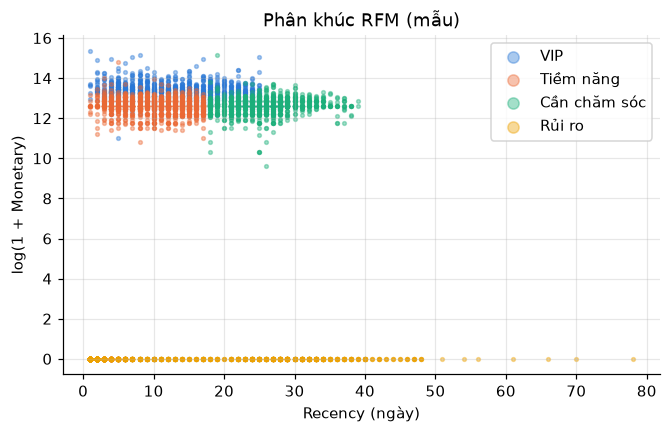

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for i, s in enumerate(fe.SEGMENT_LABELS):
    d = rfm[rfm["segment"] == s].sample(min(1500, (rfm["segment"] == s).sum()), random_state=1)
    ax.scatter(d["recency_days"], np.log1p(d["monetary_total"]), s=6, alpha=0.4, color=C[i], label=s)
ax.set_xlabel("Recency (ngày)"); ax.set_ylabel("log(1 + Monetary)"); ax.legend(markerscale=3); ax.set_title("Phân khúc RFM (mẫu)");